# Reproduce the paper: bank retreat, meander cut-off and bed stability on the lower Semliki River

**Nafula, M. and Kakooza, C. (2026).** *Bank retreat, meander cut-off and bed stability on the lower Semliki River,
Albertine Rift: 26 years of Landsat and Sentinel-2 with a 75-year gauging record.* Preprint, Zenodo,
https://doi.org/10.5281/zenodo.24367442

This notebook recomputes, from the published annual water masks, every planform number of the paper:
Tables 2–5 and Figures 2 and 4–7. Run it top to bottom (*Run all*). It needs only `numpy`, `scipy` and `matplotlib`,
runs in about two minutes, and works the same on a laptop or in Google Colab
([open in Colab](https://colab.research.google.com/github/Kaitale/semliki-sem9.7-geomorphic-evolution/blob/main/reproduce_paper.ipynb)).
If the data archive or the analysis module is not beside the notebook, the first cell downloads them from the
GitHub repository that mirrors the Zenodo record.

| Step | What it reproduces |
|---|---|
| 1 | load the 27 Landsat (2000–2026, 30 m) and 11 Sentinel-2 (2016–2026, 10 m) low-flow masks |
| 2 | erosion and deposition between the 2000–04 and 2020–26 composites (Table 2, Fig. 2) |
| 3 | low-flow width by zone and year (Fig. 4) |
| 4 | bank-position regression on 4,090 transects, three records (Table 3, Fig. 5, Fig. 6) |
| 5 | bends, 50-year setbacks and the fastest bends (Table 4, Fig. 7) |
| 6 | meander necks (Table 5) |
| 7 | this run against the numbers printed in the paper |

The specific-gauge (Fig. 8) and altimetry (Fig. 9) analyses use the Bweramule gauging record and Hydroweb series,
which are not redistributed here; Section 8 explains how to run them on those data.

## 0. Set-up

In [1]:
import os, sys, glob, csv, re, zipfile, urllib.request
REPO_RAW = "https://raw.githubusercontent.com/Kaitale/semliki-sem9.7-geomorphic-evolution/main/"
NEED = {"semliki_bankmig.py": "semliki_bankmig.py", "data_masks_and_results.zip": "data_masks_and_results.zip"}
for local, remote in NEED.items():
    if not os.path.exists(local) and not (local.endswith(".zip") and os.path.isdir("data")):
        print("downloading", remote, "...")
        urllib.request.urlretrieve(REPO_RAW + remote, local)
if not os.path.isdir("data"):
    zipfile.ZipFile("data_masks_and_results.zip").extractall(".")

import numpy as np
from scipy import ndimage
from scipy.spatial import cKDTree
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
sys.path.insert(0, os.path.abspath("."))
import semliki_bankmig as M

DATA, OUT = os.path.abspath("data"), os.path.abspath("outputs")
os.makedirs(OUT, exist_ok=True)
GAUGE_STATION_M = 8250.0            # baseline chainage of the Bweramule gauge (km 0)
ZONES = [("10-0 km above the gauge", -10.5, 0), ("km 0-20", 0, 20), ("km 20-40", 20, 40),
         ("km 40-60", 40, 60), ("km 60-92", 60, 92.5)]
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#E6EBEF"})
print("ready:", len(glob.glob(os.path.join(DATA, "masks", "*", "*.npz"))), "masks")

ready: 38 masks


## 1. The annual low-flow water masks
Each `.npz` holds `water` and `valid` (cloud-free) rasters on one UTM 35N grid and its affine `transform`.

In [2]:
def load_masks(folder, years=None):
    masks, T = {}, None
    for p in sorted(glob.glob(os.path.join(DATA, "masks", folder, "*.npz")), key=M.year_of):
        y = M.year_of(p)
        if years and not (years[0] <= y <= years[1]):
            continue
        w, v, t = M.read_mask(p); T = t; masks[y] = (w.astype(bool), v.astype(bool))
    return masks, T

L, TL = load_masks("landsat_2000_2026")
S2, TS = load_masks("sentinel2_2016_2026")
print("Landsat   : %d masks %d-%d, grid %s, pixel %.0f m" % (len(L), min(L), max(L), L[min(L)][0].shape, TL[0]))
print("Sentinel-2: %d masks %d-%d, grid %s, pixel %.0f m" % (len(S2), min(S2), max(S2), S2[min(S2)][0].shape, TS[0]))

# the published reach line (25 m stations) and its chainage below the gauge
pub = list(csv.DictReader(open(os.path.join(DATA, "results", "landsat_2000_2026", "transects.csv"))))
BASE = np.array([[float(r["x"]), float(r["y"])] for r in pub]); BASE_S = np.array([float(r["station_m"]) for r in pub])
BKM = (BASE_S - GAUGE_STATION_M) / 1000.0
_tree = cKDTree(BASE)
km_of_xy = lambda xy: BKM[_tree.query(np.asarray(xy))[1]]
print("reach line: %d stations from km %.1f to km %.1f" % (len(BASE), BKM[0], BKM[-1]))

Landsat   : 27 masks 2000-2026, grid (1315, 1174), pixel 30 m
Sentinel-2: 11 masks 2016-2026, grid (3942, 3522), pixel 10 m
reach line: 4090 stations from km -8.2 to km 94.0


## 2. Where the channel moved, 2000–04 to 2020–26 (Table 2, Fig. 2)
Majority composites per epoch, keeping water connected to the main channel within 600 m of the reach line. Land in 2000–04 that is channel in 2020–26 is *eroded*; the reverse is *deposited or abandoned*.

In [3]:
x0, dx, y0, dy = TL[2], TL[0], TL[5], TL[4]; H, Wd = L[min(L)][0].shape
EXT = [x0, x0 + Wd * dx, y0 + H * dy, y0]
base = np.zeros((H, Wd), bool)
ci = np.clip(((BASE[:, 0] - x0) / dx).astype(int), 0, Wd - 1); ri = np.clip(((BASE[:, 1] - y0) / dy).astype(int), 0, H - 1)
base[ri, ci] = True
dist, (ii, jj) = ndimage.distance_transform_edt(~base, return_indices=True)
kmb = np.full((H, Wd), np.nan); kmb[ri, ci] = BKM; KMGRID = kmb[ii, jj]
CORR = dist * dx <= 600.0

def main_channel(w):
    lab, n = ndimage.label(w, structure=np.ones((3, 3)))
    if n == 0:
        return w
    hit = np.unique(lab[ndimage.binary_dilation(base, iterations=3) & w]); hit = hit[hit > 0]
    return np.isin(lab, hit[ndimage.sum(w, lab, hit) >= 30])

def composite(ys):
    ws = sum((L[y][0] & L[y][1]).astype(float) for y in ys); vs = sum(L[y][1].astype(float) for y in ys)
    return main_channel((np.where(vs > 0, ws / np.maximum(vs, 1), 0) >= 0.5) & CORR), vs > 0

EPOCHS = [(2000, 2004), (2005, 2009), (2010, 2014), (2015, 2019), (2020, 2026)]
COMP = {e: composite([y for y in L if e[0] <= y <= e[1]]) for e in EPOCHS}
(W0, V0), (W1, V1) = COMP[EPOCHS[0]], COMP[EPOCHS[-1]]
both = V0 & V1
ERO, DEP, STAY = W1 & ~W0 & both, W0 & ~W1 & both, W0 & W1
ha = lambda m: m.sum() * dx * dx / 1e4
print("eroded %.1f ha | deposited/abandoned %.1f ha | stable %.1f ha | eroded share of 2020-26 channel %.0f %%"
      % (ha(ERO), ha(DEP), ha(STAY), 100 * ha(ERO) / ha(W1)))
span = 2023 - 2002
T2 = []
for name, lo, hi in ZONES:
    zm = (KMGRID >= lo) & (KMGRID < hi); Lm = (hi - lo) * 1000.0
    e_, d_ = ha(ERO & zm), ha(DEP & zm)
    T2.append([name, round(e_, 1), round(d_, 1), round((e_ + d_) * 1e4 / 2 / Lm / span, 2),
               round(ha(W0 & zm) * 1e4 / Lm), round(ha(W1 & zm) * 1e4 / Lm)])
print("\nTable 2  %-24s %9s %10s %15s %7s %7s" % ("zone", "eroded ha", "deposit ha", "reworked m/yr", "w0 m", "w1 m"))
for r in T2:
    print("         %-24s %9.1f %10.1f %15.2f %7d %7d" % tuple(r))

eroded 265.1 ha | deposited/abandoned 298.8 ha | stable 418.1 ha | eroded share of 2020-26 channel 39 %

Table 2  zone                     eroded ha deposit ha   reworked m/yr    w0 m    w1 m
         10-0 km above the gauge       40.5       52.4            2.11      86      75
         km 0-20                       72.6       63.2            1.62      76      81
         km 20-40                      85.4       53.1            1.65      68      84
         km 40-60                      39.2       31.1            0.84      72      76
         km 60-92                      27.4       15.9            0.32      34      38


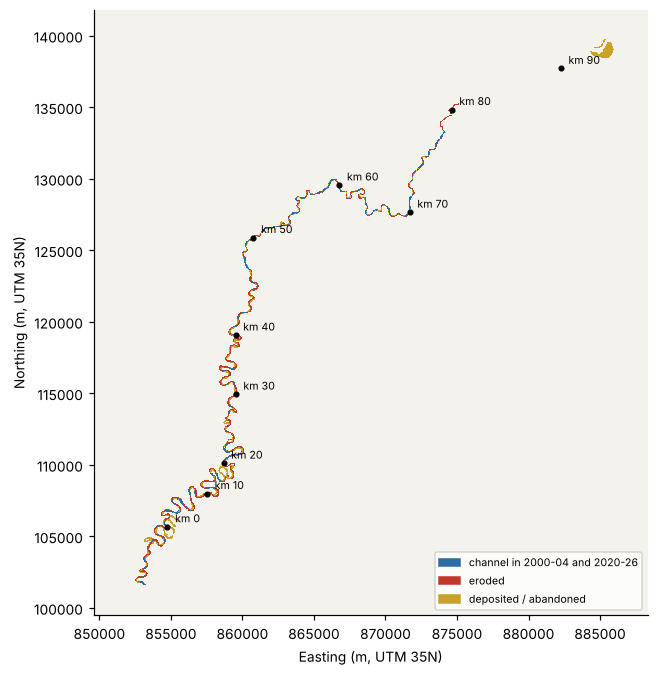

In [4]:
lay = np.full((H, Wd), np.nan); lay[STAY] = 0; lay[ERO] = 1; lay[DEP] = 2
lay = ndimage.grey_dilation(np.nan_to_num(lay, nan=-1), size=(2, 2)); lay = np.where(lay < 0, np.nan, lay)
fig, ax = plt.subplots(figsize=(6.5, 7.2)); ax.grid(False); ax.set_facecolor("#F4F2EC")
ax.imshow(lay, extent=EXT, cmap=ListedColormap(["#2E6CA4", "#C0392B", "#C9A227"]), vmin=0, vmax=2, interpolation="nearest")
for k in range(0, 95, 10):
    i = int(np.argmin(np.abs(BKM - k))); ax.plot(*BASE[i], "o", ms=3, color="k")
    ax.annotate("km %d" % k, BASE[i], xytext=(5, 3), textcoords="offset points", fontsize=7)
ax.set_xlim(BASE[:, 0].min() - 3000, BASE[:, 0].max() + 3000); ax.set_ylim(BASE[:, 1].min() - 2500, BASE[:, 1].max() + 2500)
ax.set_aspect("equal"); ax.set_xlabel("Easting (m, UTM 35N)"); ax.set_ylabel("Northing (m, UTM 35N)")
ax.legend(handles=[Patch(color="#2E6CA4", label="channel in 2000-04 and 2020-26"), Patch(color="#C0392B", label="eroded"),
                   Patch(color="#C9A227", label="deposited / abandoned")], loc="lower right", fontsize=7)
fig.savefig(os.path.join(OUT, "fig2_channel_change.png"), dpi=300, bbox_inches="tight"); plt.show()

## 3. Low-flow width by zone and year (Fig. 4)
A mask is rejected for the width series if it departs more than 35 % from the zone median in any zone above km 60.

masks rejected for the width series: [2002]
10-0 km above the gauge    width trend -0.30 m/yr
km 0-20                    width trend +0.44 m/yr
km 20-40                   width trend +0.96 m/yr
km 40-60                   width trend +0.52 m/yr
km 60-92                   width trend +0.51 m/yr


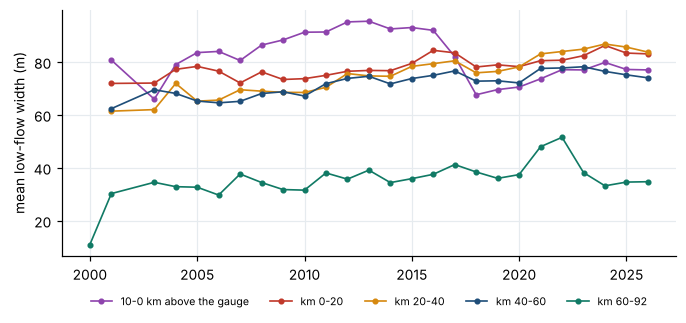

In [5]:
rows = []
for y in sorted(L):
    w, v = L[y]; mc = main_channel(w & v & CORR); rec = {"year": y}
    for name, lo, hi in ZONES:
        zm = CORR & (KMGRID >= lo) & (KMGRID < hi); vf = (v & zm).sum() / max(zm.sum(), 1)
        rec[name] = (mc & zm).sum() * dx * dx / vf / ((hi - lo) * 1000) if vf > 0.6 else None
    rows.append(rec)
med = {n: np.median([r[n] for r in rows if r[n] is not None]) for n, _, _ in ZONES}
BAD = [r["year"] for r in rows if any(r[n] is not None and abs(r[n] / med[n] - 1) > .35 for n, _, _ in ZONES[:-1])]
print("masks rejected for the width series:", BAD)
fig, ax = plt.subplots(figsize=(7.2, 2.9))
TREND = {}
for (name, lo, hi), col in zip(ZONES, ["#8E44AD", "#C0392B", "#D68910", "#1F4E79", "#117A65"]):
    ok = [r for r in rows if r["year"] not in BAD and r[name] is not None]
    yy, ww = [r["year"] for r in ok], [r[name] for r in ok]
    ax.plot(yy, ww, "o-", ms=3, lw=1.1, color=col, label=name); TREND[name] = np.polyfit(yy, ww, 1)[0]
    print("%-26s width trend %+.2f m/yr" % (name, TREND[name]))
ax.set_ylabel("mean low-flow width (m)"); ax.legend(fontsize=7, ncol=5, frameon=False, loc="upper center", bbox_to_anchor=(.5, -.12))
fig.savefig(os.path.join(OUT, "fig4_width_by_year.png"), dpi=300, bbox_inches="tight"); plt.show()

## 4. Bank retreat on 4,090 transects, three records (Table 3, Figs. 5–6)
Transects every 25 m, 600 m either side of the reach line. Each bank position is regressed on time (DSAS linear-regression rate with its 95 % interval). A bank erodes significantly when rate − CI95 > 0. Setback over 50 years = 50 (rate + CI95) + 2 σ_pos + 2 × 4 m bank allowance.

Tables 3–5 of the paper are computed here from the published per-transect results in `data/results/` (exact). Section 7 re-runs the whole transect analysis from the masks and compares.

In [6]:
def _num(v):
    if v in ("", "None", None): return None
    if v in ("True", "False"): return v == "True"
    try: return float(v)
    except ValueError: return v
def load_results(name):
    rd = lambda f: [{k: _num(v) for k, v in r.items()} for r in csv.DictReader(open(os.path.join(DATA, "results", name, f)))]
    T, B, N = rd("transects.csv"), rd("bends.csv"), rd("necks.csv")
    for r, k in zip(T, km_of_xy([[r["x"], r["y"]] for r in T])): r["km"] = float(k)
    for b in B: b["km_apex"] = float(km_of_xy([[b["apex_x"], b["apex_y"]]])[0])
    S_ = np.array([r["station_m"] for r in T])
    for n in N: n["km"] = float(BKM[int(np.argmin(np.abs(BASE_S - n["upstream_station_m"])))])
    return {"transects": T, "bends": B, "necks": N}
PUB = {n: load_results(n) for n in ("landsat_2000_2026", "landsat_2016_2026", "sentinel2_2016_2026")}
for n, R_ in PUB.items():
    print("%-20s %d transects, %d bends, %d necks" % (n, len(R_["transects"]), len(R_["bends"]), len(R_["necks"])))

landsat_2000_2026    4090 transects, 139 bends, 2 necks
landsat_2016_2026    4090 transects, 139 bends, 2 necks
sentinel2_2016_2026  4090 transects, 139 bends, 2 necks


In [7]:
def zone_rates(R):
    out = []
    for zname, lo, hi in ZONES:
        v = [(max(r[r["outer_bank"] + "_rate"], 0.0), r[r["outer_bank"] + "_eroding"]) for r in R["transects"]
             if lo <= r["km"] < hi and r[r["outer_bank"] + "_rate"] is not None and r[r["outer_bank"] + "_n"] >= 5]
        er = [x for x, e in v if e]
        out.append((len(er) / max(len(v), 1), np.median(er) if er else np.nan, np.percentile([x for x, _ in v], 90)))
    return out
def bend_p90_by_zone(R, kmax=88):
    out = []
    for zname, lo, hi in ZONES:
        b = [x["outer_rate_p90"] for x in R["bends"] if x["outer_rate_p90"] is not None and lo <= x["km_apex"] < min(hi, kmax)]
        s = [x["setback_p90_m"] for x in R["bends"] if x["setback_p90_m"] is not None and lo <= x["km_apex"] < min(hi, kmax)]
        out.append((np.median(b) if b else np.nan, np.median(s) if s else np.nan))
    return out
ZR = {n: zone_rates(R) for n, R in PUB.items()}; BZ = {n: bend_p90_by_zone(R) for n, R in PUB.items()}
print("Table 3. Outer-bank retreat (m/yr): share eroding (L 2000-26); median of eroding / P90 of all, three records; bend P90 and setback")
print("%-24s %6s %13s %13s %13s %12s %14s" % ("zone", "share", "L 2000-26", "L 2016-26", "S2 2016-26", "bend P90 L(S2)", "setback L(S2)"))
for i, (z, _, _) in enumerate(ZONES):
    a, b, c = ZR["landsat_2000_2026"][i], ZR["landsat_2016_2026"][i], ZR["sentinel2_2016_2026"][i]
    print("%-24s %5.0f%% %6.1f / %-5.1f %6.1f / %-5.1f %6.1f / %-5.1f %5.1f (%.1f) %8.0f (%.0f)"
          % (z, 100 * a[0], a[1], a[2], b[1], b[2], c[1], c[2], BZ["landsat_2000_2026"][i][0], BZ["sentinel2_2016_2026"][i][0],
             BZ["landsat_2000_2026"][i][1], BZ["sentinel2_2016_2026"][i][1]))

Table 3. Outer-bank retreat (m/yr): share eroding (L 2000-26); median of eroding / P90 of all, three records; bend P90 and setback
zone                      share     L 2000-26     L 2016-26    S2 2016-26 bend P90 L(S2)  setback L(S2)
10-0 km above the gauge     70%    2.6 / 5.6      3.6 / 7.7      2.9 / 6.4     4.5 (5.0)      327 (344)
km 0-20                     67%    3.0 / 7.2      3.3 / 5.5      3.1 / 5.1     4.7 (4.1)      307 (310)
km 20-40                    63%    2.8 / 5.4      3.3 / 4.4      2.7 / 4.5     5.0 (4.3)      408 (312)
km 40-60                    49%    1.4 / 2.6      2.7 / 3.0      2.2 / 2.5     1.5 (1.7)      155 (179)
km 60-92                    35%    0.9 / 1.6      2.1 / 1.8      1.4 / 1.2     1.0 (0.6)      141 (111)


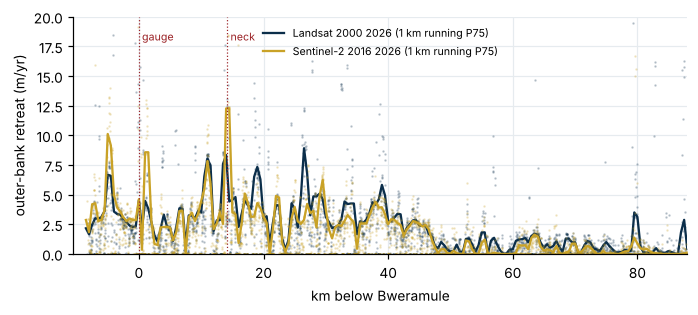

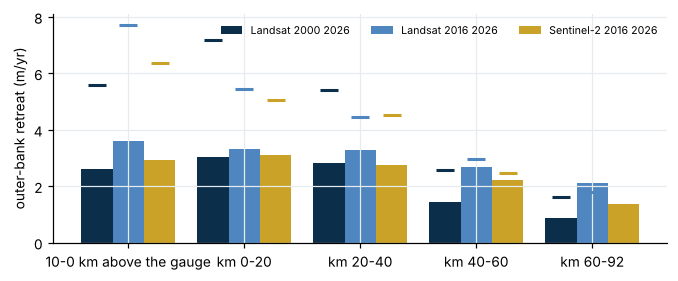

In [8]:
def outer(R, kmax=88):
    k = np.array([r["km"] for r in R["transects"] if r[r["outer_bank"] + "_rate"] is not None and r["km"] <= kmax])
    v = np.array([max(r[r["outer_bank"] + "_rate"], 0) for r in R["transects"] if r[r["outer_bank"] + "_rate"] is not None and r["km"] <= kmax])
    o = np.argsort(k); return k[o], v[o]
fig, ax = plt.subplots(figsize=(7.2, 2.8))
for name, col in (("landsat_2000_2026", "#0B2E4A"), ("sentinel2_2016_2026", "#C9A227")):
    k, v = outer(PUB[name]); ax.plot(k, v, ".", ms=1.2, color=col, alpha=.25)
    cen = np.arange(-10, 88.5, .5)
    p75 = [np.percentile(v[(k >= c - .5) & (k < c + .5)], 75) if ((k >= c - .5) & (k < c + .5)).sum() > 5 else np.nan for c in cen]
    ax.plot(cen, p75, color=col, lw=1.5, label=name.replace("_", " ").replace("landsat", "Landsat").replace("sentinel2", "Sentinel-2") + " (1 km running P75)")
for x_, lab in ((0, "gauge"), (14.2, "neck")):
    ax.axvline(x_, color="#9B2226", lw=.8, ls=":"); ax.text(x_ + .5, 18, lab, fontsize=7, color="#9B2226")
ax.set_ylim(0, 20); ax.set_xlim(-10.5, 88); ax.set_xlabel("km below Bweramule"); ax.set_ylabel("outer-bank retreat (m/yr)")
ax.legend(fontsize=7, frameon=False)
fig.savefig(os.path.join(OUT, "fig5_retreat_along_river.png"), dpi=300, bbox_inches="tight"); plt.show()

fig, ax = plt.subplots(figsize=(7.2, 2.7)); w = .27
for j, (name, col) in enumerate((("landsat_2000_2026", "#0B2E4A"), ("landsat_2016_2026", "#4F86BF"), ("sentinel2_2016_2026", "#C9A227"))):
    x = np.arange(len(ZONES)) + (j - 1) * w
    ax.bar(x, [z[1] for z in ZR[name]], w, color=col, label=name.replace("_", " ").replace("landsat", "Landsat").replace("sentinel2", "Sentinel-2"))
    ax.plot(x, [z[2] for z in ZR[name]], "_", ms=12, mew=2, color=col)
ax.set_xticks(range(len(ZONES))); ax.set_xticklabels([z[0] for z in ZONES]); ax.set_ylabel("outer-bank retreat (m/yr)")
ax.legend(fontsize=7, frameon=False, ncol=3)
fig.savefig(os.path.join(OUT, "fig6_retreat_by_zone.png"), dpi=300, bbox_inches="tight"); plt.show()

## 5. Bends, setbacks and the fastest bends (Table 4, Fig. 7)
Bend P90 = 90th percentile of the outer-bank rates within a bend; bends beyond km 88 (delta shoreline) are excluded.

125 bends within km 88; typical bend (median bend P90) 2.39 m/yr; 22 % at >= 5 m/yr; 7 above 10 m/yr
50-year setback: median 205 m, P75 373 m, P90 578 m, max 989 m
  Sentinel-2: median 214 m, P75 300 m, P90 398 m

Table 4. Fastest bends (Landsat 2000-2026)
   km   bend P90 (m/yr)  transects  radius (m)
  18.5         13.4           19        121
  27.8         13.1           23        136
  14.1         12.6           40        141
  31.9         11.8           53        206
  26.6         11.2           25        140
   0.3         10.9           25        161
  -0.1         10.6           22         92
  38.7          9.8           26         94


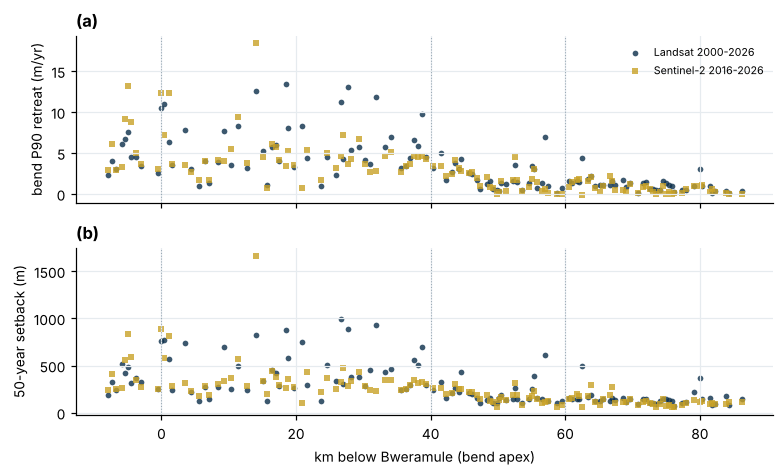

In [9]:
R = PUB["landsat_2000_2026"]
B = [b for b in R["bends"] if b["outer_rate_p90"] is not None and b["km_apex"] <= 88]
p90 = np.array([b["outer_rate_p90"] for b in B]); sb = np.array([b["setback_p90_m"] for b in B if b["setback_p90_m"] is not None])
print("%d bends within km 88; typical bend (median bend P90) %.2f m/yr; %d %% at >= 5 m/yr; %d above 10 m/yr"
      % (len(B), np.median(p90), round(100 * np.mean(p90 >= 5)), (p90 > 10).sum()))
print("50-year setback: median %.0f m, P75 %.0f m, P90 %.0f m, max %.0f m" % (np.median(sb), np.percentile(sb, 75), np.percentile(sb, 90), sb.max()))
for name in ("sentinel2_2016_2026",):
    s2 = np.array([b["setback_p90_m"] for b in PUB[name]["bends"] if b["setback_p90_m"] is not None and b["km_apex"] <= 88])
    print("  Sentinel-2: median %.0f m, P75 %.0f m, P90 %.0f m" % (np.median(s2), np.percentile(s2, 75), np.percentile(s2, 90)))
print("\nTable 4. Fastest bends (Landsat 2000-2026)\n   km   bend P90 (m/yr)  transects  radius (m)")
for b in sorted(B, key=lambda b: -b["outer_rate_p90"])[:8]:
    print("%6.1f %12.1f %12d %10.0f" % (b["km_apex"], b["outer_rate_p90"], b["n_transects"], b["radius_m"]))

fig, (a1, a2) = plt.subplots(2, 1, figsize=(7.2, 4.4), sharex=True)
for name, col, mk in (("landsat_2000_2026", "#0B2E4A", "o"), ("sentinel2_2016_2026", "#C9A227", "s")):
    bb = [b for b in PUB[name]["bends"] if b["outer_rate_p90"] is not None and b["km_apex"] <= 88]
    lab = "Landsat 2000-2026" if name.startswith("landsat") else "Sentinel-2 2016-2026"
    a1.scatter([b["km_apex"] for b in bb], [b["outer_rate_p90"] for b in bb], s=14, marker=mk, color=col, alpha=.8, lw=0, label=lab)
    a2.scatter([b["km_apex"] for b in bb if b["setback_p90_m"]], [b["setback_p90_m"] for b in bb if b["setback_p90_m"]], s=14, marker=mk, color=col, alpha=.8, lw=0)
for x_ in (0, 40, 60):
    a1.axvline(x_, color="#9AA9B5", lw=.7, ls=":"); a2.axvline(x_, color="#9AA9B5", lw=.7, ls=":")
a1.set_ylabel("bend P90 retreat (m/yr)"); a1.legend(fontsize=7, frameon=False); a1.set_title("(a)", loc="left", fontweight="bold")
a2.set_ylabel("50-year setback (m)"); a2.set_xlabel("km below Bweramule (bend apex)"); a2.set_title("(b)", loc="left", fontweight="bold")
fig.tight_layout(); fig.savefig(os.path.join(OUT, "fig7_bends_setbacks.png"), dpi=300, bbox_inches="tight"); plt.show()

## 6. Meander necks (Table 5)
A neck is a pair of transects more than 1 km apart along the river whose banks are less than about 150 m apart across the land.

In [10]:
S = np.array([r["station_m"] for r in R["transects"]])
def rate_at(st):
    r = R["transects"][int(np.argmin(np.abs(S - st)))]
    v = [r[s + "_rate"] for s in ("left", "right") if r[s + "_rate"] is not None]; return max(v) if v else np.nan
for n in R["necks"]:
    r1, r2 = rate_at(n["upstream_station_m"]), rate_at(n["downstream_station_m"])
    print("neck at km %.1f: %d m across, bypassing %.1f km of river; limbs retreat %.1f and %.1f m/yr -> about %.0f years at face value"
          % (n["km"], n["neck_width_m"], n["bypassed_length_m"] / 1000, r1, r2, n["neck_width_m"] / max(r1 + r2, 1e-6)))

neck at km 14.2: 97 m across, bypassing 1.7 km of river; limbs retreat 12.5 and 11.8 m/yr -> about 4 years at face value
neck at km 33.2: 144 m across, bypassing 1.6 km of river; limbs retreat 4.7 and 0.1 m/yr -> about 30 years at face value


## 7. Re-run the transect analysis from the masks
This repeats the bank tracing, regression, bend detection and neck search for the three records (about one minute) and compares the result with the published files and with the paper. Differences of a few per cent in bend-level statistics come from where bend boundaries fall on the curvature sign changes.

In [11]:
RECORDS = {"landsat_2000_2026": (L, TL, 15.0, None), "landsat_2016_2026": (L, TL, 12.0, (2016, 2026)),
           "sentinel2_2016_2026": (S2, TS, 10.0, None)}
RES = {}
for name, (masks, T, reg, yrs) in RECORDS.items():
    mk = {y: m for y, m in masks.items() if not yrs or yrs[0] <= y <= yrs[1]}
    Rr = M.analyse(mk, T, BASE, spacing=25.0, half=600.0, registration=reg, design_life=50.0, bank_height=4.0, presmoothed=True)
    for row, k in zip(Rr["transects"], km_of_xy(Rr["base"])): row["km"] = float(k)
    for b in Rr["bends"]: b["km_apex"] = float(km_of_xy([[b["apex_x"], b["apex_y"]]])[0])
    for n in Rr["necks"]:
        i = int(np.argmin(np.abs(Rr["s"] - n["upstream_station_m"]))); n["km"] = float(km_of_xy(Rr["base"][i:i + 1])[0])
    M.write_outputs(Rr, os.path.join(OUT, name)); RES[name] = Rr
for name in RES:
    a, b = PUB[name]["transects"], RES[name]["transects"]
    ra = np.array([r[r["outer_bank"] + "_rate"] if r[r["outer_bank"] + "_rate"] is not None else np.nan for r in a])
    rb = np.array([r[r["outer_bank"] + "_rate"] if r[r["outer_bank"] + "_rate"] is not None else np.nan for r in b])
    ok = np.isfinite(ra) & np.isfinite(rb)
    zr_new, zr_pub = zone_rates(RES[name]), zone_rates(PUB[name])
    print("%-20s outer-bank rates: %.0f %% of transects identical to 0.01 m/yr, median |diff| %.2f m/yr; "
          "zone medians differ by at most %.2f m/yr; bends %d (published %d)"
          % (name, 100 * np.mean(np.abs(ra[ok] - rb[ok]) < 0.011), np.median(np.abs(ra[ok] - rb[ok])),
             np.nanmax([abs(x[1] - y[1]) for x, y in zip(zr_new, zr_pub)]), len(RES[name]["bends"]), len(PUB[name]["bends"])))

landsat_2000_2026    outer-bank rates: 97 % of transects identical to 0.01 m/yr, median |diff| 0.00 m/yr; zone medians differ by at most 0.01 m/yr; bends 129 (published 139)
landsat_2016_2026    outer-bank rates: 97 % of transects identical to 0.01 m/yr, median |diff| 0.00 m/yr; zone medians differ by at most 0.02 m/yr; bends 129 (published 139)
sentinel2_2016_2026  outer-bank rates: 96 % of transects identical to 0.01 m/yr, median |diff| 0.00 m/yr; zone medians differ by at most 0.01 m/yr; bends 129 (published 139)


### The paper, the published files and this run

In [12]:
Bn = [b for b in RES["landsat_2000_2026"]["bends"] if b["outer_rate_p90"] is not None and b["km_apex"] <= 88]
sbn = np.array([b["setback_p90_m"] for b in Bn if b["setback_p90_m"] is not None])
rows_ = [("eroded (ha)", 265.1, ha(ERO), ha(ERO)), ("deposited / abandoned (ha)", 298.8, ha(DEP), ha(DEP)),
         ("stable channel (ha)", 418.1, ha(STAY), ha(STAY)),
         ("bends within km 88", 125, len(B), len(Bn)),
         ("median bend P90, Landsat 2000-26 (m/yr)", 2.4, float(np.median(p90)), float(np.median([b["outer_rate_p90"] for b in Bn]))),
         ("50-yr setback, median of bends (m)", 205, float(np.median(sb)), float(np.median(sbn))),
         ("50-yr setback, P90 of bends (m)", 578, float(np.percentile(sb, 90)), float(np.percentile(sbn, 90))),
         ("fastest bend P90 (m/yr)", 13.4, float(p90.max()), float(max(b["outer_rate_p90"] for b in Bn)))]
print("%-42s %8s %16s %10s" % ("quantity", "paper", "published files", "re-run"))
for r in rows_:
    print("%-42s %8s %16.1f %10.1f" % r)
print()
print("figures written to", OUT)

quantity                                      paper  published files     re-run
eroded (ha)                                   265.1            265.1      265.1
deposited / abandoned (ha)                    298.8            298.8      298.8
stable channel (ha)                           418.1            418.1      418.1
bends within km 88                              125            125.0      118.0
median bend P90, Landsat 2000-26 (m/yr)         2.4              2.4        2.3
50-yr setback, median of bends (m)              205            205.0      205.0
50-yr setback, P90 of bends (m)                 578            577.8      591.9
fastest bend P90 (m/yr)                        13.4             13.4       13.4

figures written to /home/claude/zen/repo97v2/outputs


## 8. The bed: specific gauge and altimetry (Figs. 8–9)

These two analyses are short and are given here as functions to run on the source data.

* **Specific gauge.** For each epoch, regress stage on ln *Q* over the gaugings of that epoch and read the stage at 150, 200 and
  250 m³/s inside the gauged range. The Bweramule gaugings (1950–1975 current meter, 2024–2025 ADCP) are held by the
  Ministry of Water and Environment, Uganda, and are available on request.
* **Altimetry.** For each Hydroweb virtual station (https://hydroweb.next.theia-land.fr) with at least six years of data,
  take the annual 10th percentile of water level and fit a least-squares trend.

In [13]:
def specific_gauge(stage_m, Q_m3s, at=(150, 200, 250)):
    """stage for fixed discharges from a fit of stage on ln Q; None outside the gauged range"""
    h, q = np.asarray(stage_m, float), np.asarray(Q_m3s, float)
    b, a = np.polyfit(np.log(q), h, 1)
    return {x: (a + b * np.log(x) if q.min() <= x <= q.max() else None) for x in at}

def low_water_trend(dates, heights, min_per_year=6):
    """annual 10th percentile of altimetric water level and its trend (m/yr)"""
    by = {}
    for d, h in zip(dates, heights):
        by.setdefault(int(str(d)[:4]), []).append(float(h))
    yy = sorted(y for y, v in by.items() if len(v) >= min_per_year)
    lo = [np.percentile(by[y], 10) for y in yy]
    return yy, lo, (np.polyfit(yy, lo, 1)[0] if len(yy) >= 4 else np.nan)

# example with made-up numbers, to show the call
print(specific_gauge([16.6, 17.0, 17.3, 17.6], [150, 190, 230, 280]))

{150: np.float64(16.60944143776338), 200: np.float64(17.07005771389941), 250: np.float64(17.42733945472581)}
